<a href="https://colab.research.google.com/github/23070075-creator/NNDL-Lab/blob/main/NNDL_PRACTICAL_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.0587 - val_loss: 0.0309
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - loss: 0.0248 - val_loss: 0.0200
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0182 - val_loss: 0.0157
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0150 - val_loss: 0.0137
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0136 - val_loss: 0.0128
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
Encoded data shape: (10, 32)


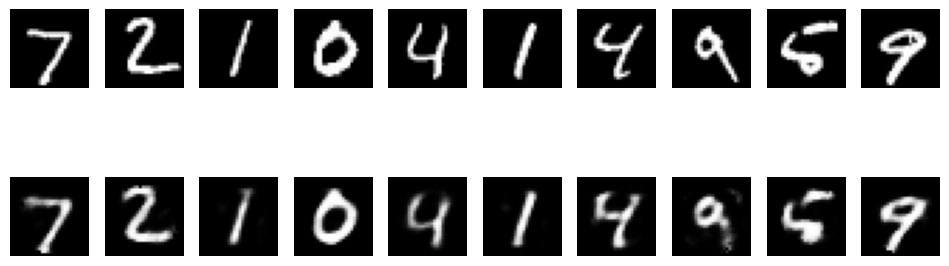

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

inputs = Input(shape=(784,))
encoded = Dense(128, activation="relu")(inputs)
encoded = Dense(32, activation="relu")(encoded)
decoded = Dense(128, activation="relu")(encoded)
outputs = Dense(784, activation="sigmoid")(decoded)

autoencoder = Model(inputs, outputs)
encoder = Model(inputs, encoded)

autoencoder.compile(optimizer="adam", loss="mse")

autoencoder.fit(
    x_train, x_train,
    epochs=5,
    batch_size=256,
    validation_data=(x_test, x_test)
)

reconstructed = autoencoder.predict(x_test[:10])
print("Encoded data shape:", encoder.predict(x_test[:10]).shape)

plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.show()